In [18]:
import math
import torch
import random
import numpy as np
import matplotlib.pyplot as plt

In [19]:
def f(x):
    return 2 * x ** 2 - 6 * x + 5
# 4x - 6

In [20]:
f(3)

5

In [21]:
xs = np.arange(-5, 5 ,0.25)
ys = f(xs)
ys

array([85.   , 78.625, 72.5  , 66.625, 61.   , 55.625, 50.5  , 45.625,
       41.   , 36.625, 32.5  , 28.625, 25.   , 21.625, 18.5  , 15.625,
       13.   , 10.625,  8.5  ,  6.625,  5.   ,  3.625,  2.5  ,  1.625,
        1.   ,  0.625,  0.5  ,  0.625,  1.   ,  1.625,  2.5  ,  3.625,
        5.   ,  6.625,  8.5  , 10.625, 13.   , 15.625, 18.5  , 21.625])

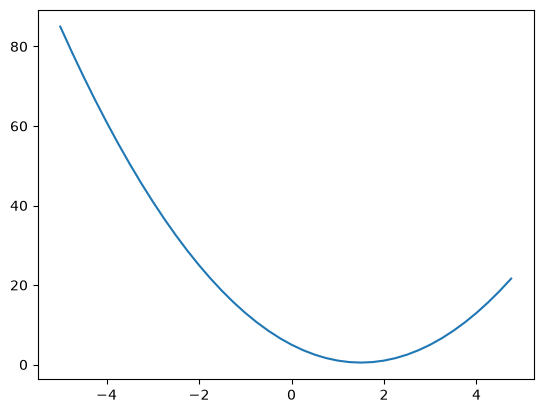

In [22]:
plt.plot(xs, ys)

In [23]:
h = 0.00000001
x = -3
(f(x + h) - f(x)) / h

-18.000000068241206

In [24]:
a = 2.0
b = -3.0
c = 10.0
d = (a * b) + c
print(d)

4.0


#### For a With respect to D 

In [25]:
h = 0.000001

# inputs
a = 2.0
b = -3.0
c = 10.0

d1 = (a * b) + c
a += h
d2 = (a * b) + c

print('d1', d1)
print('d2', d2)
print('slop :', (d2 - d1) / h)

d1 4.0
d2 3.9999969999999996
slop : -3.000000000419334


#### For b With respect to D 

In [26]:
h = 0.000001

# inputs
a = 2.0
b = -3.0
c = 10.0

d1 = (a * b) + c
b += h
d2 = (a * b) + c

print('d1', d1)
print('d2', d2)
print('slop :', (d2 - d1) / h)

d1 4.0
d2 4.000002
slop : 2.000000000279556


#### For c With respect to D 

In [27]:
h = 0.000001

# inputs
a = 2.0
b = -3.0
c = 10.0

d1 = (a * b) + c
c += h
d2 = (a * b) + c

print('d1', d1)
print('d2', d2)
print('slop :', (d2 - d1) / h)

d1 4.0
d2 4.000000999999999
slop : 0.9999999992515995


In [28]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.prev = set(_children)
        self.op = _op
        self.label = label
        self.grad = 0.0
        self._backword = lambda: None

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")

        def backword():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backword = backword
        return out

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)

    def __rmul__(self, other): # 2 * Value(2.0)  --> won't work
        return self * other

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")

        def backword():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backword = backword
        return out
    
    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supports int/float"
        out = Value(self.data**other, (self, other), f'**{other}')
        
        def backword():
            self.grad += other * (self.data ** (other - 1)) * out.grad

        out._backword = backword()
        return out

    def __truediv__(self, other): # a/b = a * b^-1
        return self * other**-1
    
    def __rtruediv__(self, other):
        return self / other

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t, (self, ), 'tanh')

        def backword():
            self.grad += (1 - t**2) * out.grad
        out._backword = backword
        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')

        def backword():
            self.grad += out.data * out.grad
        out._backword = backword
        return out

    def backword(self):
        topo = []
        visited = set()

        def build_topo(cur):
          if cur not in visited:
            visited.add(cur)
            for child in cur.prev:
              build_topo(child)
            topo.append(cur)
        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
          node._backword()

In [29]:
from graphviz import Digraph

def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v.prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangulr ('record') node for it
        dot.node(name=uid, label = "{ %s | data %.4f}" % (n.label, n.data), shape='record')
        if n.op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name=uid + n.op, lable = n.op)
            # and connect this node to it
            dot.edge(uid + n.op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2.op)

    return dot

In [30]:
#inputs
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias
b = Value(6.8813735870195432, label='b')

x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2;x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b;n.label = 'n'
o = n.tanh(); o.label = 'o'

In [31]:
o.backword()

In [32]:
class Neuron:
    def __init__(self, nin):
      self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
      self.b = Value(random.uniform(-1,1))

    def __call__(self, x):
      act = sum((x1*w1 for x1, w1 in zip(self.w,x)), self.b)
      return act.tanh()

class Layer:
    def __init__(self, nin, nout):
      self.neurons = [Neuron(nin) for _ in range(nout)]
    
    def __call__(self, x):
      outs = [n(x) for n in self.neurons]
      return outs[0] if len(outs) == 1 else outs

class MLP:
    def __init__(self, nin, nouts):
      sz = [nin] + nouts
      self.layers = [Layer(sz[i], sz[i + 1]) for i in range(len(nouts))]
    
    def __call__(self, x):
      for layer in self.layers:
        x = layer(x)
      return x